# forze e statica molecolare (Ag)

Applicazione dei concetti di *CMS 4* al sistema di 108 atomi di argento
(`fcc100a108.txt`), potenziale di Lennard-Jones con cutoff $r_c = 4.5$ Å.

Percorso: **brute force → neighbor list → energia → forze → minimizzazione**.
Ogni passo è verificato contro un riferimento (brute force o differenze finite).

Riferimento teorico: slide CMS 4. Stessi nomi di variabile (`nnbrs`, `whichnbr`,
`epot`, `force`, `fmax`, `csteep`, `nsteep`) per coerenza col corso.

## 1. Setup e lettura dei dati

Si usa la struttura `fcc100a108.txt` e le funzioni del package
`computational_course` (le stesse della teoria, già testate).

In [1]:
import sys
from pathlib import Path


def _setup_path():
    root = Path.cwd()
    for _ in range(10):
        if (root / "pyproject.toml").exists():
            break
        root = root.parent
    src = str(root / "src")
    if src not in sys.path:
        sys.path.insert(0, src)
    return root


PROJECT_ROOT = _setup_path()
(PROJECT_ROOT / "figures").mkdir(exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np

from computational_course.lennard_jones import (
    build_neighbor_list,
    lennard_jones_energy,
    lennard_jones_forces,
)
from computational_course.ovito_visualization import load_structure

FILENAME = "fcc100a108.txt"
RC = 4.5
SIGMA = 2.644
EPSILON = 0.345

txt_path, pos = load_structure(FILENAME, PROJECT_ROOT)
natoms = len(pos)
print(f"{txt_path.name}: {natoms} atomi")

fcc100a108.txt: 108 atomi


## 2. Energia potenziale: approccio "brute force"

$$U = \frac{1}{2} \sum_{i \neq j} \phi(r_{ij}), \qquad
\phi(r) = 4\varepsilon\left[\left(\frac{\sigma}{r}\right)^{12} - \left(\frac{\sigma}{r}\right)^{6}\right]$$

Il fattore $1/2$ compensa il doppio conteggio della coppia $(i,j)$.
Il doppio ciclo su tutti gli atomi costa **$O(N^2)$**: serve solo come verità di riferimento.

Come nelle slide, il fattore $1/2$ compensa il doppio conteggio della coppia $(i,j)$.

In [2]:
def epot_bruteforce(pos, eps, sigma, rc):
    epot = 0.0
    for i in range(len(pos)):
        for j in range(len(pos)):
            if i == j:
                continue
            rij = pos[i] - pos[j]
            d2 = rij @ rij
            if d2 < rc * rc:
                sr6 = (sigma * sigma / d2) ** 3
                epot += 4 * eps * (sr6**2 - sr6)
    return 0.5 * epot


epot_bf = epot_bruteforce(pos, EPSILON, SIGMA, RC)
print(f"Epot brute force: {epot_bf:.6f} eV")

Epot brute force: -173.139733 eV


## 3. Neighbor lists

I numeri atomici sono solo etichette: conta **chi è vicino a chi** entro $r_c$.
Per ogni atomo $i$ si salvano

- `nnbrs[i]`: numero di vicini di $i$;
- `whichnbr[i, k]`: etichetta del $k$-esimo vicino di $i$ (validi solo i primi `nnbrs[i]`).

Il numero di vicini non dipende dalla dimensione del sistema: dipende da densità e $r_c$.
La costruzione è ancora $O(N^2)$ (non è qui il guadagno).

In [3]:
nnbrs, whichnbr = build_neighbor_list(pos, RC)

print(f"Coordinazione media: {nnbrs.mean():.3f}")
print(f"Vicini minimi / massimi: {nnbrs.min()} / {nnbrs.max()}")
print(f"Atomo 11, primi vicini: {whichnbr[11, : nnbrs[11]]}")

Coordinazione media: 12.333
Vicini minimi / massimi: 6 / 18
Atomo 11, primi vicini: [ 5  9 10 16 17 22 23 35 51]


## 4. Energia con le neighbor lists

La somma corre solo sulle coppie in lista. Ogni coppia compare due volte
($i \to k$ e $k \to i$), quindi resta il fattore $1/2$. Il risultato **deve**
coincidere col brute force.

In [4]:
epot = lennard_jones_energy(pos, SIGMA, EPSILON, nnbrs, whichnbr)

print(f"Epot con liste : {epot:.6f} eV")
print(f"Epot brute     : {epot_bf:.6f} eV")
assert np.isclose(epot, epot_bf), "le liste non riproducono il brute force"
print("OK: la lista dei vicini riproduce l'energia brute force.")

Epot con liste : -173.139733 eV
Epot brute     : -173.139733 eV
OK: la lista dei vicini riproduce l'energia brute force.


## 5. Forze

Per un potenziale di coppia, la forza sull'atomo $k$ dovuta a $j$ è

$$\vec F_{k} = \sum_{j \neq k} -\frac{\partial \phi(r_{kj})}{\partial \vec r_k}.$$

Per Lennard-Jones, con $\Delta \vec r = \vec r_k - \vec r_j$:

$$\vec F_{k} = \sum_j \frac{24\varepsilon}{r_{kj}^2}
\left[2\left(\frac{\sigma}{r_{kj}}\right)^{12} - \left(\frac{\sigma}{r_{kj}}\right)^{6}\right] \Delta \vec r.$$

Le forze si sommano sui soli vicini (`whichnbr`).

In [5]:
force = lennard_jones_forces(pos, SIGMA, EPSILON, nnbrs, whichnbr)
fmax = np.max(np.abs(force))

print(f"Forza netta totale (deve ~0): {np.abs(force.sum(axis=0)).max():.2e} eV/Å")
print(f"fmax: {fmax:.6f} eV/Å")

Forza netta totale (deve ~0): 6.25e-16 eV/Å
fmax: 0.113839 eV/Å


### Verifica con differenze finite

La forza analitica deve coincidere con la derivata numerica dell'energia:

$$F_{i,c} \approx -\frac{U(\vec r_i + h\,\hat e_c) - U(\vec r_i - h\,\hat e_c)}{2h}.$$

Questo è il test più importante: se fallisce, il resto non ha senso.

Con sharp cutoff $\phi$ salta a $r_c$ (circa $-0.054$ eV per coppia). Le differenze finite sono valide finché nessun atomo attraversa $r_c$ entro $\pm h$; con $h=10^{-4}$ questo rischio è trascurabile.

In [6]:
H = 1e-4


def numerical_force(pos_arr, i, comp, h=H):
    p_plus = pos_arr.copy()
    p_plus[i, comp] += h
    p_minus = pos_arr.copy()
    p_minus[i, comp] -= h
    n_p, w_p = build_neighbor_list(p_plus, RC)
    n_m, w_m = build_neighbor_list(p_minus, RC)
    e_p = lennard_jones_energy(p_plus, SIGMA, EPSILON, n_p, w_p)
    e_m = lennard_jones_energy(p_minus, SIGMA, EPSILON, n_m, w_m)
    return -(e_p - e_m) / (2 * h)


err = 0.0
for i in [0, 1, 2, 18]:
    for comp in range(3):
        err = max(err, abs(numerical_force(pos, i, comp) - force[i, comp]))
assert err < 1e-6, f"forze analitiche e numeriche non coincidono: {err:.2e}"
print(f"Errore massimo analitica vs numerica: {err:.2e} eV/Å")

Errore massimo analitica vs numerica: 4.62e-08 eV/Å


## 6. Statica molecolare: steepest descent

Minimo locale di $U$ nello spazio a $3N$ dimensioni. Ci si muove lungo la forza
(gradiente negativo), finché $\vec F \to 0$:

$$\vec x_{new} = \vec x + c_{steep}\,\vec F.$$

A ogni passo si ricostruisce la lista dei vicini (gli atomi si muovono) e si
monitorano **energia** (deve scendere) e **fmax** (deve andare a zero).

$c_{steep}$ troppo grande = instabile; qui $c_{steep} = 0.001$, $n_{steep} = 2000$.

In [7]:
csteep = 0.001
nsteep = 2000

pos_min = pos.copy()
epot_hist = np.empty(nsteep)
fmax_hist = np.empty(nsteep)

for step in range(nsteep):
    nnbrs, whichnbr = build_neighbor_list(pos_min, RC)
    force = lennard_jones_forces(pos_min, SIGMA, EPSILON, nnbrs, whichnbr)
    epot_hist[step] = lennard_jones_energy(pos_min, SIGMA, EPSILON, nnbrs, whichnbr)
    fmax_hist[step] = np.max(np.abs(force))
    pos_min = pos_min + csteep * force

assert np.all(np.diff(epot_hist) <= 1e-10), "Epot non monotona"
print(f"Epot  prima: {epot_hist[0]:.4f} eV   dopo: {epot_hist[-1]:.4f} eV")
print(f"fmax  prima: {fmax_hist[0]:.4f} eV/Å  dopo: {fmax_hist[-1]:.2e} eV/Å")
print(f"Spostamento massimo di un atomo: {np.abs(pos_min - pos).max():.3e} Å")

Epot  prima: -173.1397 eV   dopo: -173.2511 eV
fmax  prima: 0.1138 eV/Å  dopo: 5.22e-04 eV/Å
Spostamento massimo di un atomo: 2.180e-02 Å


Dopo 2000 passi l'energia è stabile, mentre $f_{max}\approx 5\times10^{-4}$ eV/Å. Le slide indicano come valore tipico $10^{-5}$ eV/Å: per raggiungerlo serve aumentare nsteep (ad esempio 5000) e verificare che $E_{pot}$ non cambi più.

Con $n_{steep}=5000$ si ottiene $f_{max}\approx 5\times10^{-7}$ eV/Å, con $E_{pot}=-173.2511$ eV invariata rispetto a 2000 passi.

## 7. Grafici di convergenza

$E_{pot}$ deve scendere in modo monotono e stabilizzarsi; $f_{max}$ deve
avvicinarsi a zero (può salire di qualche passo quando cambia l'atomo critico).

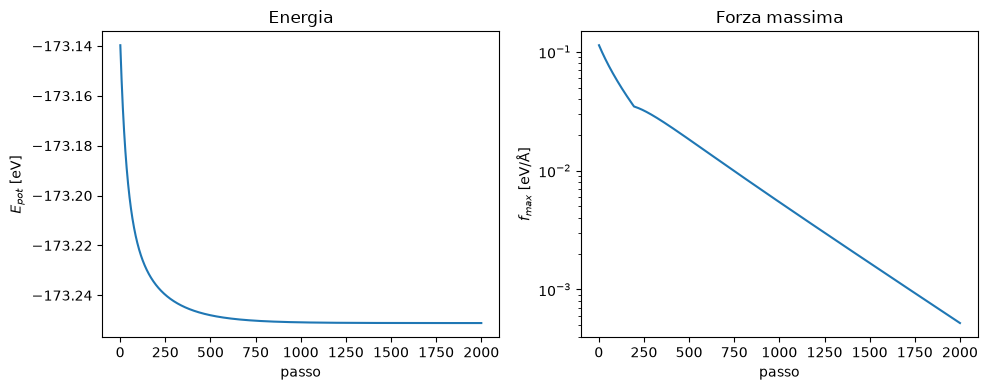

In [8]:
steps = np.arange(1, nsteep + 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(steps, epot_hist)
axes[0].set_xlabel("passo")
axes[0].set_ylabel(r"$E_{pot}$ [eV]")
axes[0].set_title("Energia")
axes[1].semilogy(steps, fmax_hist)
axes[1].set_xlabel("passo")
axes[1].set_ylabel(r"$f_{max}$ [eV/Å]")
axes[1].set_title("Forza massima")
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "steepest_descent.png", dpi=150)
plt.show()

## 8. Cutoff: sharp vs polinomiale

Il **sharp cutoff** tronca $\phi(r)$ a zero bruscamente in $r_c$: energia e forze
sono discontinue (problemi in dinamica e minimizzazione).

**Soluzione:** tra $r'$ e $r_c$ si sostituisce $\phi$ con un polinomio
$P(r) = A + Br + Cr^2 + Dr^3$ che si raccorda lisciamente:

$$P(r_c) = 0,\quad P'(r_c) = 0,\qquad P(r') = \phi(r'),\quad P'(r') = \phi'(r').$$

Ponendo $u = r' - r_c$: $\beta = \dfrac{F - 2E/u}{u^2}$, $\alpha = \dfrac{E}{u^2} - \beta r'$,
con $E = \phi(r')$, $F = \phi'(r')$, e
$A = r_c^2\alpha$, $B = r_c^2\beta - 2r_c\alpha$, $C = \alpha - 2r_c\beta$, $D = \beta$.

La scelta di $r'$: è un punto nella **coda attrattiva** ($\phi(r')<0$, $r' < r_c$), dove il
potenziale è ancora liscio. Il raccordo dipende da questa scelta: $r'$ più vicino a $r_c$
dà una correzione più stretta, $r'$ più interno una correzione più invasiva della coda fisica.

Nella zona di giunzione la forza di coppia diventa
$$\vec f_{kj} = -\frac{1}{r}\frac{dP}{dr}\,\Delta\vec r
= -\frac{B}{r}\,\Delta\vec r - 2C\,\Delta\vec r - 3D\,r\,\Delta\vec r .$$

**Nota:** in questo notebook il polinomio è solo **illustrativo**. Energia, forze e
minimizzazione usano il **sharp cutoff**; per usarlo davvero `lennard_jones_energy` e
`lennard_jones_forces` andrebbero riscritte con $\phi$ sostituito da $P$ tra $r'$ e $r_c$.

In [9]:
def phi_lj(r, eps, sigma):
    sr6 = (sigma / r) ** 6
    return 4 * eps * (sr6**2 - sr6)


def dphi_lj(r, eps, sigma):
    sr6 = (sigma / r) ** 6
    return 4 * eps * (6 * sr6 - 12 * sr6**2) / r


rprime = 4.0

E = phi_lj(rprime, EPSILON, SIGMA)
F = dphi_lj(rprime, EPSILON, SIGMA)
u = rprime - RC
beta = (F - 2 * E / u) / u**2
alpha = E / u**2 - beta * rprime
A = RC**2 * alpha
B = RC**2 * beta - 2 * RC * alpha
C = alpha - 2 * RC * beta
D = beta


def phi_poly(r):
    return A + B * r + C * r**2 + D * r**3


def dphi_poly(r):
    return B + 2 * C * r + 3 * D * r**2


print("P(rc),  P'(rc)  :", phi_poly(RC), dphi_poly(RC))
print("P(r'),  phi(r') :", phi_poly(rprime), E)
print("P'(r'), phi'(r'):", dphi_poly(rprime), F)

P(rc),  P'(rc)  : -5.684341886080802e-14 1.4210854715202004e-14
P(r'),  phi(r') : -0.10550275735582204 -0.10550275735581964
P'(r'), phi'(r'): 0.14385329490355048 0.14385329490355095


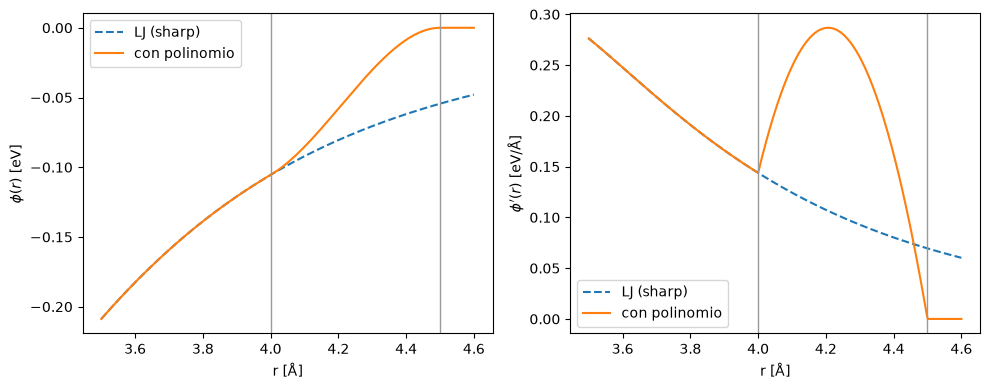

In [10]:
r = np.linspace(3.5, 4.6, 400)
p_lj = phi_lj(r, EPSILON, SIGMA)
dp_lj = dphi_lj(r, EPSILON, SIGMA)
p_poly = A + B * r + C * r**2 + D * r**3
dp_poly = B + 2 * C * r + 3 * D * r**2
p_join = np.where(r < rprime, p_lj, np.where(r < RC, p_poly, 0.0))
dp_join = np.where(r < rprime, dp_lj, np.where(r < RC, dp_poly, 0.0))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(r, p_lj, "--", label="LJ (sharp)")
axes[0].plot(r, p_join, label="con polinomio")
axes[0].set_ylabel(r"$\phi(r)$ [eV]")
axes[1].plot(r, dp_lj, "--", label="LJ (sharp)")
axes[1].plot(r, dp_join, label="con polinomio")
axes[1].set_ylabel(r"$\phi'(r)$ [eV/Å]")
for ax in axes:
    ax.axvline(rprime, color="0.6", lw=1)
    ax.axvline(RC, color="0.6", lw=1)
    ax.set_xlabel("r [Å]")
    ax.legend()
fig.tight_layout()
fig.savefig(PROJECT_ROOT / "figures" / "cutoff_polinomiale.png", dpi=150)
plt.show()

## 9. Riepilogo

| Passo | Cosa si fa | Verifica |
| --- | --- | --- |
| Brute force | $U = \tfrac12\sum_{i\neq j}\phi(r_{ij})$, $O(N^2)$ | riferimento |
| Neighbor list | `nnbrs`, `whichnbr` entro $r_c$ | coordinazione ragionevole |
| Energia | somma sulle coppie in lista | coincide col brute force |
| Forze | $\vec F = \sum_j K_{kj}\,\Delta\vec r_{kj}$ | differenze finite |
| Steepest descent | $\vec x \to \vec x + c_{steep}\vec F$ | $E_{pot}\downarrow$, $f_{max}\to 0$ |

Con $K_{kj} = \dfrac{24\varepsilon}{r_{kj}^2}\left[2\left(\sigma/r_{kj}\right)^{12} - \left(\sigma/r_{kj}\right)^{6}\right]$ (la tabella usa la forma compatta).

### Note di fisica

- Le liste **non cambiano la fisica**, solo il costo. Se il risultato cambia, c'è un bug.
- Il **sharp cutoff** introduce discontinuità in energia e forza a $r_c$; il polinomio le elimina.
- Lo **steepest descent** trova il minimo locale più vicino, non quello globale: dipende dal punto di partenza.
- $c_{steep}$ grande è veloce ma instabile: verificare sempre che l'energia scenda.

### Prossimo passo

Costruzione della lista in modo efficiente (cell list) e ricostruzione solo quando serve
(criterio dello **skin**, lista di Verlet): non trattato nelle slide.

# QUINDI

In conclusione, la cosa principale da ricordare è il comportamento di `nnbrs` e `whichnbr`: si studi questo pseudocodice, perché è fondamentale per il calcolo delle forze e non solo.

![Pseudocodice della costruzione della lista dei vicini e del calcolo dell'energia](../../figures/pseudocodice_lista_vicini_energia.png)


### Come leggere `nnbrs` e `whichnbr`

- `nnbrs[i]` = **quanti** vicini ha l'atomo `i` entro $r_c$ (dipende dal cutoff scelto).
- `whichnbr[i, k]` = indice del **k-esimo** vicino dell'atomo `i`, valido solo per $k <$ `nnbrs[i]`.

`nnbrs[i]` è il numero scritto sul biglietto, `whichnbr[i]` è l'elenco dei nomi: il numero dice fin dove leggere l'elenco. Esempio (atomo 11, $r_c=4.5$ Å):

`nnbrs[11] = 9`

`whichnbr[11] = [5 9 10 16 17 22 23 35 51 | 0 ... 0]`

I primi 9 valori sono i vicini; il resto sono zeri di riempimento. Gli zeri finali **non** significano "nessun vicino": l'atomo 0 è un vicino valido come gli altri. Per questo serve `nnbrs` per sapere quanti elementi leggere.

La matrice è `natoms × natoms` perché non si sa in anticipo quanti vicini abbia un atomo: costo memoria $O(N^2)$. In produzione si usa la cell list, dimensionata sul numero medio di vicini.

Coppia valida: `(i, whichnbr[i, k])` con `k < nnbrs[i]`.